<a href="https://colab.research.google.com/github/ibader85/PredictiveAnalytics/blob/main/26_K_Means_Clustering_Using_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

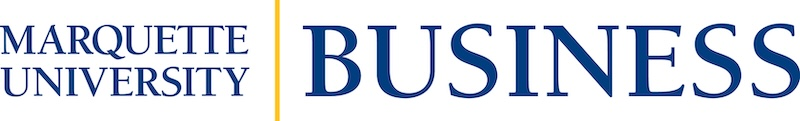

# BUAN 3065: Unlocking Business Insights with Predictive Analytics
# Hierarchical Clustering Using Python

Instructor: Dr. Badar Al Lawati

**Disclaimer:** the content in this notebook is based on the content in Chapter 14 of Business Analytics by Sanjiv Jaggia, Alison Kelly, Kevin Lertwachara and Leida Chen. ISBN10: 126692602X | ISBN13: 9781266926020

In [ ]:
# Import the dataset

import pandas as pd
myData = pd.read_excel('/content/CandyBars.xlsx')
myData.head()

,Brands,Calories,Fat,Protein,Carb
0,Peanut Butter Twix,311.0,18.5,5.3,31.4
1,Baby Ruth,275.0,13.0,3.2,39.0
2,Caramel Twix,284.5,14.0,2.5,37.5
3,5th Avenue,279.5,12.5,4.5,41.0
4,Snickers,273.0,14.0,4.5,34.0


In [ ]:
# We exclude the Brands column from the analysis and standardize the other variables using the scale function

from sklearn.preprocessing import scale
myData_std = scale(myData.drop('Brands', axis = 1))

In situations where data standardization is not needed, simply
modify the data frame by only including those variables that will
be used in the clustering process

we import Scikit-Learn’s KMeans
class and create a variable of the class named kModel.

* The first
option, n_clusters, specifies the number of clusters.

* The second
option, n_init, specifies the number of times the k-means
clustering process is run with different random initial cluster
centers for selecting the best cluster structure

- we
use n_clusters = 4 because we preselected to divide the data into
four clusters.

- We use n_init = 10 to ask the algorithm to run the kmeans
clustering process 10 times

In [ ]:
from sklearn.cluster import KMeans

kModel = KMeans(n_clusters = 4, n_init = 10, random_state = 321)
kResult = kModel.fit(myData_std)

# Ignore the warning message as it does not affect the processing or results in this example

The resulting kResult variable has several important attributes.
The cluster_centers_ attribute provides the cluster center values
for each cluster

In [ ]:
kResult.cluster_centers_

array([[-0.18920772,  0.348691  ,  0.02887134, -0.53594874],
       [-1.43597904, -1.27403771, -0.9619597 ,  0.07070092],
       [ 1.2099598 ,  0.74425046,  1.03174373,  0.21951521],
       [ 0.44039421, -1.8930523 , -1.35416365,  2.59439453]])

In [ ]:
# To display a clearer version of the cluster center information, we present the cluster centers in a data frame with column names

column_names = ['Calories', 'Fat', 'Protein', 'Carb']
Cluster_centers=pd.DataFrame(kResult.cluster_centers_,columns=column_names)
Cluster_centers

,Calories,Fat,Protein,Carb
0,-0.189208,0.348691,0.028871,-0.535949
1,-1.435979,-1.274038,-0.961960,0.070701
2,1.209960,0.744250,1.031744,0.219515
3,0.440394,-1.893052,-1.354164,2.594395


In [ ]:
myData['Cluster'] = kResult.labels_
myData.head()
myData.tail()

,Brands,Calories,Fat,Protein,Carb,Cluster
32,Raisinets,185.5,7.0,2.0,32.0,1
33,Chunkie,173.5,10.0,3.0,20.0,0
34,York Peppermint Pattie,149.0,4.0,1.5,33.5,1
35,After Eight Mints,147.0,5.5,1.0,31.5,1
36,Twizzlers Cherry Nibs,139.0,1.1,1.0,31.7,1


To obtain the summary statistics for the four clusters in
unstandardized values, we concatenate the information about the
size of each cluster and average values of the variables into a new
data frame

In [ ]:
pd.concat([myData.groupby('Cluster').size().rename('Count'), myData.groupby('Cluster').mean(numeric_only=True)], axis= 1)

,Count,Calories,Fat,Protein,Carb
Cluster,,,,,
0,19,218.789474,11.947368,3.184211,27.552632
1,6,172.166667,5.350000,1.500000,33.033333
2,9,271.111111,13.555556,4.888889,34.377778
3,3,242.333333,2.833333,0.833333,55.833333


The silhouette plot shows how close each observation in one cluster is to observations in the other clusters; therefore, it is indicative of the robustness of the clustering structure.

Using Scikit-Learn's silhouette _samples function, we compute the silhouette coefficients, which are values in the range from - 1 to + 1

A silhouette coefficient value that is closer to +1 indicates that the observation is well matched to its own cluster and poorly matched to neighboring clusters

If most observations are positive and have values close to + 1, then the clustering structure is appropriate

On the other hand, if many points have a low or negative value for the silhouette coefficient, then the clustering structure may have too many or too few clusters

In [ ]:
from sklearn.metrics import silhouette_samples
Silhouette_coef = silhouette_samples(myData_std, kResult.labels_)
Silhouette_coef.mean ()

np.float64(0.333776208318553)

To visualize the silhouette plot, we first create a data frame with the silhouette coefficients sorted and grouped by cluster and then plot the data using a bar plot

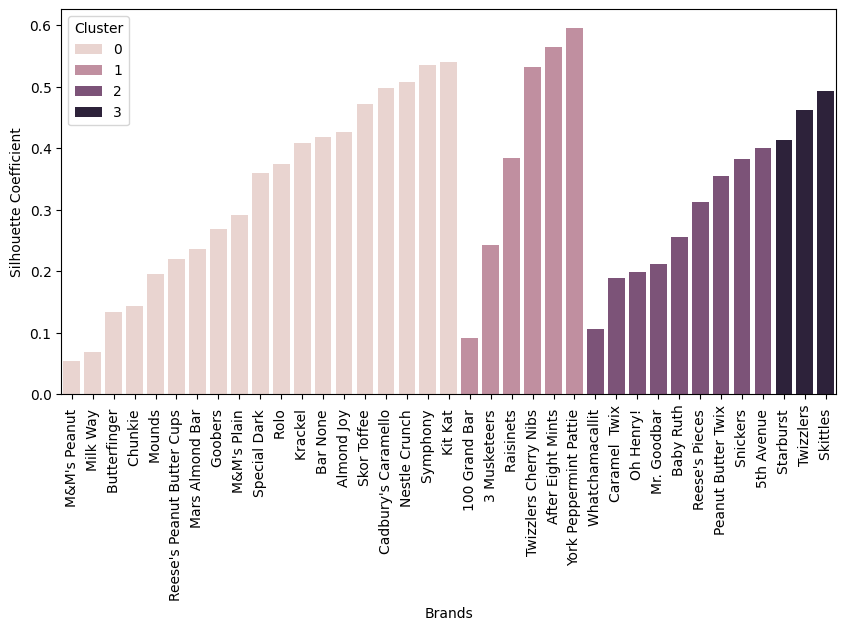

In [ ]:
SilhouetteData = pd.DataFrame ({'Cluster' : kResult.labels_, 'Silhouette Coefficient': Silhouette_coef, 'Brands' : myData.Brands}). sort_values(['Cluster', 'Silhouette Coefficient' ])

import seaborn as sns
import matplotlib.pyplot as plt

plt.subplots(figsize = (10, 5))
sns. barplot(x = 'Brands', y = 'Silhouette Coefficient', hue = 'Cluster', data = SilhouetteData, dodge = False)
plt.xticks(rotation = 'vertical');